# EDA -> DSC PJATK Catalogue Quality Challenge

Sprawdzam czym oferty z błędem (target 1) różnią się od poprawnych (target 0).

Dane: train.csv ma 16 000 ofert z odpowiedzią, test.csv ma 10 000 ofert bez odpowiedzi, a oof_tree_v2.csv to przewidywania modelu Piotra do analizy pomyłek.

In [94]:
from pydoc import text

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

train = pd.read_csv("../data/train.csv")
test = pd.read_csv("../data/test.csv")
oof = pd.read_csv("../data/handoff/oof_tree_v2.csv")

In [95]:
train.shape, test.shape, oof.shape

((16000, 11), (10000, 10), (16000, 5))

In [96]:
train.head()

,id,seller_id,title,description,declared_category,brand,condition,price_pln,shipping_weight_kg,pack_size,target
0,OFR_191714271,SEL_7523257,recording mic support — pack of one — Mira A513,Pack of one main items. Microphone stand by Mi...,audio,Mira,used,70.43,5.233,1.0,1
1,OFR_517640949,SEL_2053194,in-ear cable headphones — quantity 2 — Noro E315,Included main items: 2. Wired earbuds by Noro....,computers,Noro,used,28.95,0.119,2.0,1
2,OFR_634805877,SEL_8620752,Tenso digital food balance / standard / quanti...,Included main items: 1. Kitchen scale by Tenso...,kitchen,Tenso,new,62.05,0.412,1.0,0
3,OFR_643990737,SEL_8396386,litter scoop — five main items — Velo ...,Cat tray cleaning shovel by Velto. Variant: st...,pets,Velto,used,102.26,0.499,5.0,0
4,OFR_260742748,SEL_5029882,LAPTOP SLEEVE — PACK OF FIVE — ASTER F219,Variant: standard. Also includes 3 pcs of free...,computers,Aster,used,144.84,0.856,5.0,0


In [97]:
train["target"].value_counts(normalize=True).map("{:.1%}".format)

target
0    83.0%
1    17.0%
Name: proportion, dtype: object

83% ofert jest poprawnych, a 17% ma błąd, więc klasy są niezbalansowane.

## Braki danych

In [98]:
train.isna().mean().map("{:.1%}".format).sort_values(ascending=False)

shipping_weight_kg    6.0%
brand                 5.9%
description           4.2%
price_pln             3.9%
pack_size             3.0%
title                 2.9%
declared_category     2.3%
id                    0.0%
seller_id             0.0%
condition             0.0%
target                0.0%
dtype: object

In [99]:
missing_by_target = train.isna().groupby(train["target"]).mean().T.sort_values(1, ascending=False)
missing_by_target.map("{:.1%}".format)

target,0,1
shipping_weight_kg,6.0%,6.2%
brand,6.0%,5.4%
price_pln,3.8%,4.3%
description,4.4%,3.7%
pack_size,3.0%,3.2%
title,3.0%,2.6%
declared_category,2.3%,2.5%
seller_id,0.0%,0.0%
id,0.0%,0.0%
condition,0.0%,0.0%


Braki występują w 2-6% wartości, najwięcej w wadze i marce. Odsetek braków jest prawie taki sam w ofertach poprawnych i błędnych, więc brak danych nie jest sygnałem błędu.

## Kategorie

In [100]:
categories = (
    train.groupby("declared_category", dropna=False)["target"]
    .agg(odsetek_bledow="mean", liczba_ofert="count")
    .sort_values("odsetek_bledow", ascending=False)
)
categories["odsetek_bledow"] = categories["odsetek_bledow"].map("{:.1%}".format)
categories

,odsetek_bledow,liczba_ofert
declared_category,,
music,36.6%,735
garden,21.1%,1331
NaN,18.2%,374
kitchen,17.3%,2253
pets,17.3%,863
computers,16.0%,2759
beauty,15.9%,1622
audio,15.0%,2535
sport,14.0%,1837


In [101]:
train[(train["declared_category"] == "music") & (train["target"] == 1)][["title", "declared_category"]].head(10)

,title,declared_category
167,Mira C640: large tambourine (pack of three),music
241,Velto E280: standard multiport computer adapte...,music
493,EXTERNAL SSD — 1 UNITS — VELTO F364,music
501,ireless headphones — 1-pack — Noro D396,music
503,COMPUTER CALL HEADPHONES — ONE MAIN ITEM...,music
586,Tenso D359: standard external SSD (1 units),music
590,POETRY COLLECTION — PACK OF THREE — MIRA B672,music
606,Tenso mechanical keyboard / standard / pack of...,music
608,audio interface — pack of two — Mira E272,music
809,OVER-EAR BLUETOOTH HEDSET — QUANTITY 1 — NORO ...,music


Kategoria music ma 37% błędów (średnio 17%). Wśród błędnych ofert music większość tytułów to produkty z innych kategorii (SSD, słuchawki, książki), więc częstym błędem jest podmieniona kategoria. Tekst jest zaszumiony: literówki, twarde spacje, różne formaty liczby sztuk.

In [102]:
train[(train["declared_category"] == "music") & (train["target"] == 0)][["title", "declared_category"]].head(10)

,title,declared_category
80,Velto clip-on pitch meter / compact / three ma...,music
101,Velto D454: standard folding sheet holder (pac...,music
140,recording mic support — 1 units — Tenso C750,music
159,TENSO C438: LARGE FOLDING SHEET HOLDER (PACK O...,music
163,Mira USB microphone / standard / one main items,music
201,Aster wooden percussion beaters / large / one ...,music
259,USB MICROPHONE — PACK OF TWO — TENSO E622,music
296,Mira E477: standard printed piano score collec...,music
336,Tenso hand percussion frame / large / pack of one,music
361,VELTO A636: STANDARD CLIP-ON PITCH METER (QUAN...,music


Poprawne oferty music to faktycznie sprzęt muzyczny (mikrofony, nuty, perkusja), co potwierdza, że w błędnych ofertach kategoria została podmieniona.

## Ceny

In [103]:
train.groupby("target")["price_pln"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
target,,,,,,,,
0,12773.0,138.20,182.78,2.75,40.16,77.25,162.11,3049.33
1,2604.0,181.16,316.29,0.97,36.89,79.81,192.25,3464.27


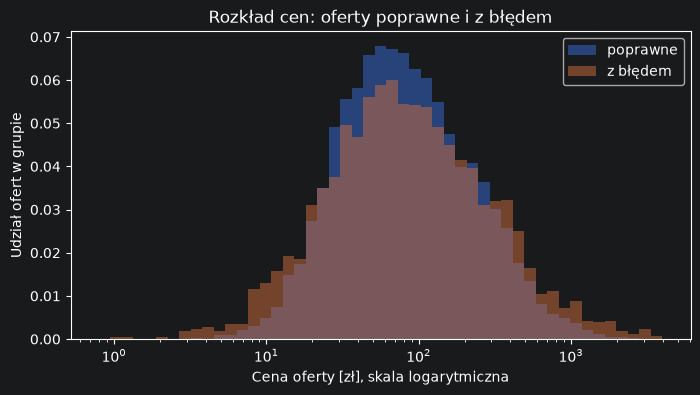

In [104]:
labels = {0: "poprawne", 1: "z błędem"}
# skala log, inaczej tanie oferty zlewają się przy zerze
bins = np.logspace(-0.1, 3.6, 50)

plt.figure(figsize=(8, 4))
for target_value in [0, 1]:
    prices = train.loc[train["target"] == target_value, "price_pln"].dropna()
    # udział w grupie zamiast liczby ofert
    weights = np.ones(len(prices)) / len(prices)
    plt.hist(prices, bins=bins, weights=weights, alpha=0.5, label=labels[target_value])

plt.xscale("log")
plt.xlabel("Cena oferty [zł], skala logarytmiczna")
plt.ylabel("Udział ofert w grupie")
plt.title("Rozkład cen: oferty poprawne i z błędem")
plt.legend()
plt.show()

Mediana cen jest podobna, ale oferty z błędem częściej mają ceny skrajne, bardzo niskie albo bardzo wysokie. Możliwe, że błąd ceny polega na jej mocnym zawyżeniu lub zaniżeniu (to hipoteza, nie znamy typu błędu).

### Cena względem kategorii

Cena oferty podzielona przez medianę ceny w jej deklarowanej kategorii (1.0 = cena typowa dla kategorii).

In [105]:
category_median = train.groupby("declared_category")["price_pln"].transform("median")
train["price_vs_category"] = train["price_pln"] / category_median
train.groupby("target")["price_vs_category"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
target,,,,,,,,
0,12475.0,1.48,1.63,0.05,0.56,0.99,1.78,30.89
1,2539.0,1.97,3.24,0.03,0.50,1.05,2.18,61.02


### Ile ofert ma skrajną cenę

Skrajna cena: ponad 5x albo poniżej 0.2x mediany kategorii (próg przyjęty umownie).

In [106]:
extrema_price = (train["price_vs_category"] > 5) | (train["price_vs_category"] < 0.2)
extrema_price.groupby(train["target"]).mean().map("{:.1%}".format)

target
0     5.6%
1    13.8%
Name: price_vs_category, dtype: object

### Cena za sztukę względem kategorii

Cena dotyczy całej paczki, więc dzielimy ją przez pack_size i porównujemy z medianą ceny za sztukę w kategorii.

In [107]:
train["price_per_item"] = train["price_pln"] / train["pack_size"]
item_median = train.groupby("declared_category")["price_per_item"].transform("median")
train["item_price_vs_category"] = train["price_per_item"] / item_median
train.groupby("target")["item_price_vs_category"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
target,,,,,,,,
0,12098.0,1.31,1.10,0.07,0.60,1.01,1.67,16.35
1,2455.0,1.65,2.18,0.03,0.42,0.91,2.03,30.94


In [108]:
extrema_item = (train["item_price_vs_category"] > 5) | (train["item_price_vs_category"] < 0.2)
extrema_item.groupby(train["target"]).mean().map("{:.1%}".format)

target
0     2.8%
1    13.9%
Name: item_price_vs_category, dtype: object

Po przeliczeniu ceny na jedną sztukę skrajne ceny ma 2.8% poprawnych i 13.9% błędnych ofert (wcześniej 5.6% i 13.8%). Cena za sztukę daje o połowę mniej fałszywych alarmów, więc lepiej wskazuje błąd ceny niż cena całej paczki. W analizie pominięto oferty bez ceny, kategorii lub pack_size (ok. 1 450).

## Waga za sztukę względem kategorii

In [109]:
train["weight_per_item"] = train["shipping_weight_kg"] / train["pack_size"]
weight_median = train.groupby("declared_category")["weight_per_item"].transform("median")
train["item_weight_vs_category"] = train["weight_per_item"] / weight_median
train.groupby("target")["item_weight_vs_category"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
target,,,,,,,,
0,11835.0,1.8,2.21,0.09,0.62,1.00,2.03,19.68
1,2405.0,2.1,3.83,0.03,0.45,0.95,2.14,53.07


In [110]:
extrema_weight = (train["item_weight_vs_category"] > 5) | (train["item_weight_vs_category"] < 0.2)
extrema_weight.groupby(train["target"]).mean().map("{:.1%}".format)

target
0     8.1%
1    15.1%
Name: item_weight_vs_category, dtype: object

Skrajną wagę za sztukę ma 8.1% poprawnych i 15.1% błędnych ofert. Waga odróżnia błędy słabiej niż cena za sztukę (2.8% i 13.9%), bo nawet poprawne wagi mocno się różnią. Możliwy powód: waga obejmuje opakowanie, a produkty mają różne warianty rozmiaru. W analizie pominięto ok. 1 760 ofert bez wagi, kategorii lub pack_size.

## Liczba sztuk w opisie a pack_size

In [111]:
import sys
sys.path.append("..")
from model_tree_v2 import counts_v2

# liczba sztuk znaleziona w tytule i opisie:
text_counts = [counts_v2(t) | counts_v2(d) for t, d in zip(train["title"], train["description"])]
train["text_quantity"] = [next(iter(c)) if len(c) == 1 else np.nan for c in text_counts]
train["text_quantity"].notna().mean()

np.float64(0.999375)

In [112]:
# jak często liczba z tekstu nie zgadza się z pack_size, osobno dla poprawnych i błędnych:
known = train["text_quantity"].notna() & train["pack_size"].notna()
mismatch = train.loc[known, "text_quantity"] != train.loc[known, "pack_size"]
mismatch.groupby(train.loc[known, "target"]).mean().map("{:.1%}".format)

target
0     0.0%
1    14.9%
dtype: object

In [113]:
# Przykład niezgodności:
train.loc[known][mismatch][["title", "pack_size", "text_quantity", "target"]].head(10)

,title,pack_size,text_quantity,target
33,Aster C494: large frying pan (1 pcs),3.0,1.0,1
99,Velto wired typing keyboard / standard / quant...,3.0,1.0,1
216,NORO PLANT GROWING GUIDE / STANDARD / 1 UNITS,3.0,1.0,1
254,Mira web camera / standard / 3-pack,5.0,3.0,1
308,Aster ear cushion set / large / pack of one,5.0,1.0,1
340,MIRA A960: STANDARD FELINE CLAW BOARD (1 PCS),3.0,1.0,1
343,countertop water boiler — 1 units — Tenso C151,2.0,1.0,1
365,Tenso B407: sandard countertop water boiler (1...,3.0,1.0,1
375,adjustable screen mount — pack of one — Mira E817,5.0,1.0,1
418,Aster USB video webcam / standard / 2 units,3.0,2.0,1


Liczbę sztuk z tekstu udało się odczytać w 99.9% ofert. Niezgodność z pack_size ma 0.0% poprawnych i 14.9% błędnych ofert, więc każda taka niezgodność oznacza błąd. To najmocniejszy sygnał w EDA, ale wyłapuje tylko część błędów.

## Wnioski

- 17% ofert ma błąd
- braki danych nie są sygnałem błędu, jest ich tyle samo w poprawnych i błędnych
- music ma 37% błędów, często podmieniona kategoria (np. SSD w music)
- tekst zaszumiony, liczba sztuk zapisana na wiele sposobów
- cena za sztukę: skrajną ma 2.8% poprawnych i 13.9% błędnych, lepiej niż cena paczki
- waga za sztukę: 8.1% vs 15.1%, słabszy sygnał niż cena
- liczba sztuk z tekstu różna od pack_size: 0% poprawnych vs 14.9% błędnych, każda niezgodność to błąd

## Ograniczenia

- pominięte oferty bez ceny, wagi, kategorii lub pack_size
- progi 5x i 0.2x są umowne
- zła kategoria psuje porównanie z medianą kategorii